In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(
    "../data/raw/SeoulBikeData.csv",
    encoding="ISO-8859-1"
)

# Prepare datetime index
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)

df["DateTime"] = (
    df["Date"] +
    pd.to_timedelta(df["Hour"], unit="h")
)

ts_df = df.sort_values("DateTime").set_index("DateTime")

# Extract target time series
bike_series = ts_df["Rented Bike Count"].asfreq("h")

# Recreate chronological split
train = bike_series.iloc[:6132]
validation = bike_series.iloc[6132:7446]
test = bike_series.iloc[7446:]

# Combine training and validation data
train_val = pd.concat([train, validation])

print("Training:", len(train))
print("Validation:", len(validation))
print("Combined training + validation:", len(train_val))
print("Test:", len(test))

print("\nFinal training period:")
print(train_val.index.min(), "to", train_val.index.max())

print("\nFinal test period:")
print(test.index.min(), "to", test.index.max())

Training: 6132
Validation: 1314
Combined training + validation: 7446
Test: 1314

Final training period:
2017-12-01 00:00:00 to 2018-10-07 05:00:00

Final test period:
2018-10-07 06:00:00 to 2018-11-30 23:00:00


In [2]:
validation_results = pd.DataFrame({
    "Model": [
        "ARIMA(1,0,1)",
        "ARIMA(2,0,0)",
        "SARIMA(1,0,1)(1,0,1,24)",
        "SARIMA(1,0,1)(1,1,1,24)",
        "UCM Local Linear Trend + Seasonal(24)",
        "UCM Local Level + Seasonal(24)",
        "SVR Original Target",
        "SVR Scaled Target",
        "SVR Tuned C500"
    ],
    "MAE": [
        596.654003,
        596.641665,
        424.829288,
        418.148757,
        445.819448,
        451.681894,
        498.284510,
        488.762077,
        851.745739
    ],
    "RMSE": [
        750.157554,
        750.152466,
        609.379912,
        580.647653,
        577.896361,
        577.233022,
        753.753146,
        759.997128,
        1119.734064
    ]
})

validation_results = validation_results.sort_values("MAE")

print(validation_results.to_string(index=False))

# Save results
validation_results.to_csv(
    "../results/tables/validation_model_comparison.csv",
    index=False
)

                                Model        MAE        RMSE
              SARIMA(1,0,1)(1,1,1,24) 418.148757  580.647653
              SARIMA(1,0,1)(1,0,1,24) 424.829288  609.379912
UCM Local Linear Trend + Seasonal(24) 445.819448  577.896361
       UCM Local Level + Seasonal(24) 451.681894  577.233022
                    SVR Scaled Target 488.762077  759.997128
                  SVR Original Target 498.284510  753.753146
                         ARIMA(2,0,0) 596.641665  750.152466
                         ARIMA(1,0,1) 596.654003  750.157554
                       SVR Tuned C500 851.745739 1119.734064


In [3]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Fit the selected SARIMA model on training + validation
final_sarima = SARIMAX(
    train_val,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 24)
)

final_sarima_fit = final_sarima.fit(disp=False)

# Forecast the entire test period without updating with actual test values
sarima_test_forecast = final_sarima_fit.forecast(
    steps=len(test)
)

# Evaluate forecasts
sarima_test_mae = mean_absolute_error(
    test,
    sarima_test_forecast
)

sarima_test_rmse = np.sqrt(
    mean_squared_error(test, sarima_test_forecast)
)

print("FINAL SARIMA TEST RESULTS")
print("-------------------------")
print("MAE:", sarima_test_mae)
print("RMSE:", sarima_test_rmse)
print("Forecast observations:", len(sarima_test_forecast))

FINAL SARIMA TEST RESULTS
-------------------------
MAE: 306.8889159846268
RMSE: 437.0376499141636
Forecast observations: 1314


In [4]:
from statsmodels.tsa.statespace.structural import UnobservedComponents

# Fit UCM on training + validation
final_ucm = UnobservedComponents(
    train_val,
    level="local linear trend",
    seasonal=24
)

final_ucm_fit = final_ucm.fit(disp=False)

# Forecast the entire test period
ucm_test_forecast = final_ucm_fit.forecast(
    steps=len(test)
)

# Evaluate forecasts
ucm_test_mae = mean_absolute_error(
    test,
    ucm_test_forecast
)

ucm_test_rmse = np.sqrt(
    mean_squared_error(test, ucm_test_forecast)
)

print("FINAL UCM TEST RESULTS")
print("----------------------")
print("MAE:", ucm_test_mae)
print("RMSE:", ucm_test_rmse)
print("Forecast observations:", len(ucm_test_forecast))

FINAL UCM TEST RESULTS
----------------------
MAE: 310.7351427602708
RMSE: 438.0606203627562
Forecast observations: 1314


In [6]:
def create_features(series):
    X = pd.DataFrame(index=series.index)

    # Historical demand
    X["lag_1"] = series.shift(1)
    X["lag_2"] = series.shift(2)
    X["lag_24"] = series.shift(24)
    X["lag_48"] = series.shift(48)
    X["lag_168"] = series.shift(168)

    # Time-based features
    X["hour"] = series.index.hour
    X["day_of_week"] = series.index.dayofweek

    # Cyclical encoding
    X["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)

    X["day_sin"] = np.sin(2 * np.pi * X["day_of_week"] / 7)
    X["day_cos"] = np.cos(2 * np.pi * X["day_of_week"] / 7)

    X["is_weekend"] = (X["day_of_week"] >= 5).astype(int)

    return X

print("Feature function recreated successfully!")

Feature function recreated successfully!


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Create features from the complete historical series
X_all = create_features(bike_series)

# Keep only rows belonging to training + validation
X_train_val = X_all.loc[train_val.index]

# Remove rows with missing lag features
valid_rows = X_train_val.notna().all(axis=1)

X_train_val = X_train_val.loc[valid_rows]
y_train_val = train_val.loc[X_train_val.index]

print("SVR training observations:", len(X_train_val))

# Fit feature scaler
final_X_scaler = StandardScaler()

X_train_val_scaled = final_X_scaler.fit_transform(
    X_train_val
)

# Fit target scaler
final_y_scaler = StandardScaler()

y_train_val_scaled = final_y_scaler.fit_transform(
    y_train_val.to_numpy().reshape(-1, 1)
).ravel()

# Fit selected SVR model
final_svr = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

final_svr.fit(
    X_train_val_scaled,
    y_train_val_scaled
)

print("Final SVR model fitted successfully!")

SVR training observations: 7278
Final SVR model fitted successfully!


In [8]:
# Start with all observed data before the test period
history = train_val.copy()

svr_test_predictions = []

# Forecast recursively, one hour at a time
for timestamp in test.index:

    # Create features using historical observations and previous predictions
    temp_series = pd.concat([
        history,
        pd.Series(index=[timestamp], dtype=float)
    ])

    X_current = create_features(temp_series).iloc[[-1]]

    # Scale features
    X_current_scaled = final_X_scaler.transform(X_current)

    # Predict scaled target
    prediction_scaled = final_svr.predict(X_current_scaled)

    # Convert prediction back to original bike counts
    prediction = final_y_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    )[0, 0]

    # Store prediction
    svr_test_predictions.append(prediction)

    # Add prediction to history for the next forecast
    history.loc[timestamp] = prediction

# Convert predictions into a time series
svr_test_forecast = pd.Series(
    svr_test_predictions,
    index=test.index,
    name="SVR Forecast"
)

print("SVR test forecasting completed!")
print("Forecast observations:", len(svr_test_forecast))
print("\nFirst 5 predictions:")
print(svr_test_forecast.head())

SVR test forecasting completed!
Forecast observations: 1314

First 5 predictions:
DateTime
2018-10-07 06:00:00    135.355185
2018-10-07 07:00:00    159.687805
2018-10-07 08:00:00    202.846310
2018-10-07 09:00:00    253.601603
2018-10-07 10:00:00    340.514719
Freq: h, Name: SVR Forecast, dtype: float64


In [9]:
svr_test_mae = mean_absolute_error(
    test,
    svr_test_forecast
)

svr_test_rmse = np.sqrt(
    mean_squared_error(test, svr_test_forecast)
)

print("FINAL SVR TEST RESULTS")
print("----------------------")
print("MAE:", svr_test_mae)
print("RMSE:", svr_test_rmse)
print("Forecast observations:", len(svr_test_forecast))

FINAL SVR TEST RESULTS
----------------------
MAE: 664.4097637525877
RMSE: 881.1327737809276
Forecast observations: 1314


In [10]:
# 1. Final test metrics
test_results = pd.DataFrame({
    "Model": ["SARIMA", "UCM", "SVR"],
    "MAE": [
        sarima_test_mae,
        ucm_test_mae,
        svr_test_mae
    ],
    "RMSE": [
        sarima_test_rmse,
        ucm_test_rmse,
        svr_test_rmse
    ]
})

test_results = test_results.sort_values("MAE")

print("FINAL TEST COMPARISON")
print(test_results.to_string(index=False))

# 2. Save metrics
test_results.to_csv(
    "../results/tables/final_test_comparison.csv",
    index=False
)

# 3. Combine actual values and forecasts
forecast_comparison = pd.DataFrame({
    "Actual": test,
    "SARIMA": sarima_test_forecast,
    "UCM": ucm_test_forecast,
    "SVR": svr_test_forecast
})

# 4. Save predictions
forecast_comparison.to_csv(
    "../results/tables/final_test_predictions.csv"
)

print("\nFinal comparison and predictions saved successfully!")

FINAL TEST COMPARISON
 Model        MAE       RMSE
SARIMA 306.888916 437.037650
   UCM 310.735143 438.060620
   SVR 664.409764 881.132774

Final comparison and predictions saved successfully!


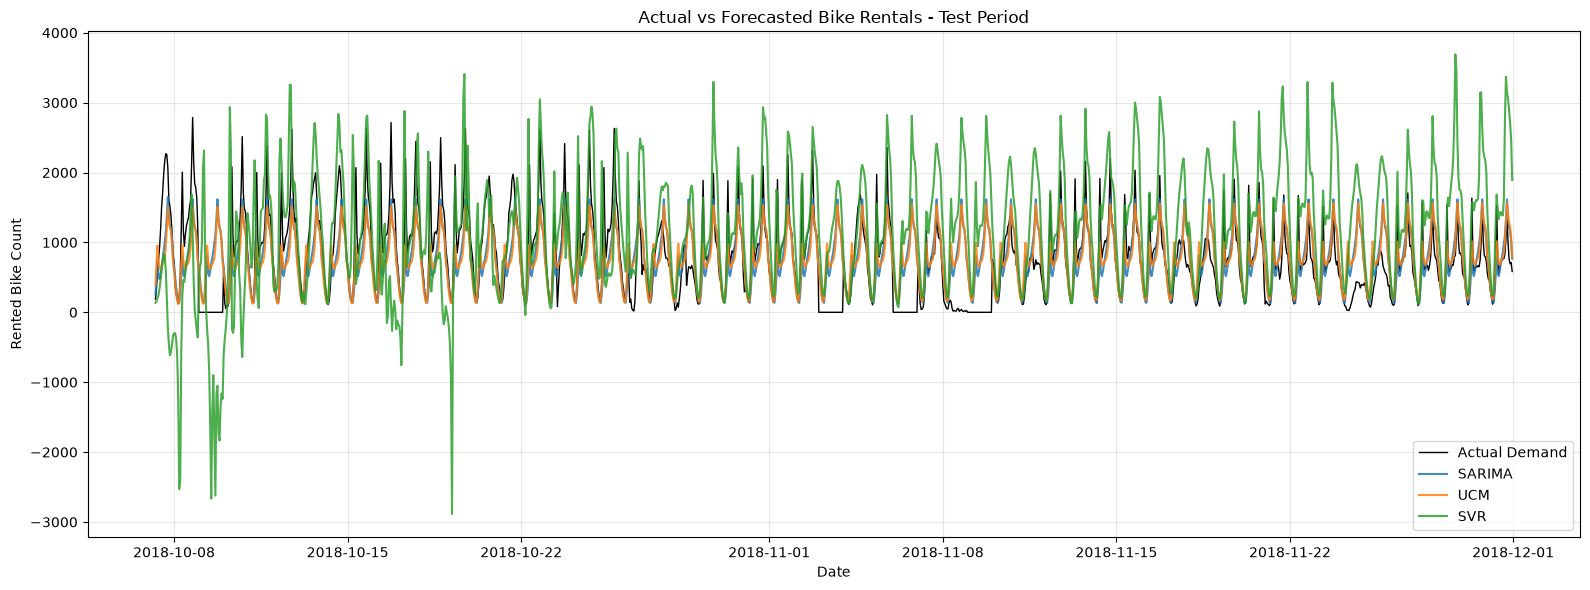

In [11]:
plt.figure(figsize=(16, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual Demand",
    color="black",
    linewidth=1
)

plt.plot(
    sarima_test_forecast.index,
    sarima_test_forecast.values,
    label="SARIMA",
    alpha=0.85
)

plt.plot(
    ucm_test_forecast.index,
    ucm_test_forecast.values,
    label="UCM",
    alpha=0.85
)

plt.plot(
    svr_test_forecast.index,
    svr_test_forecast.values,
    label="SVR",
    alpha=0.85
)

plt.title("Actual vs Forecasted Bike Rentals - Test Period")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/final_test_forecast_comparison.png",
    dpi=300
)

plt.show()

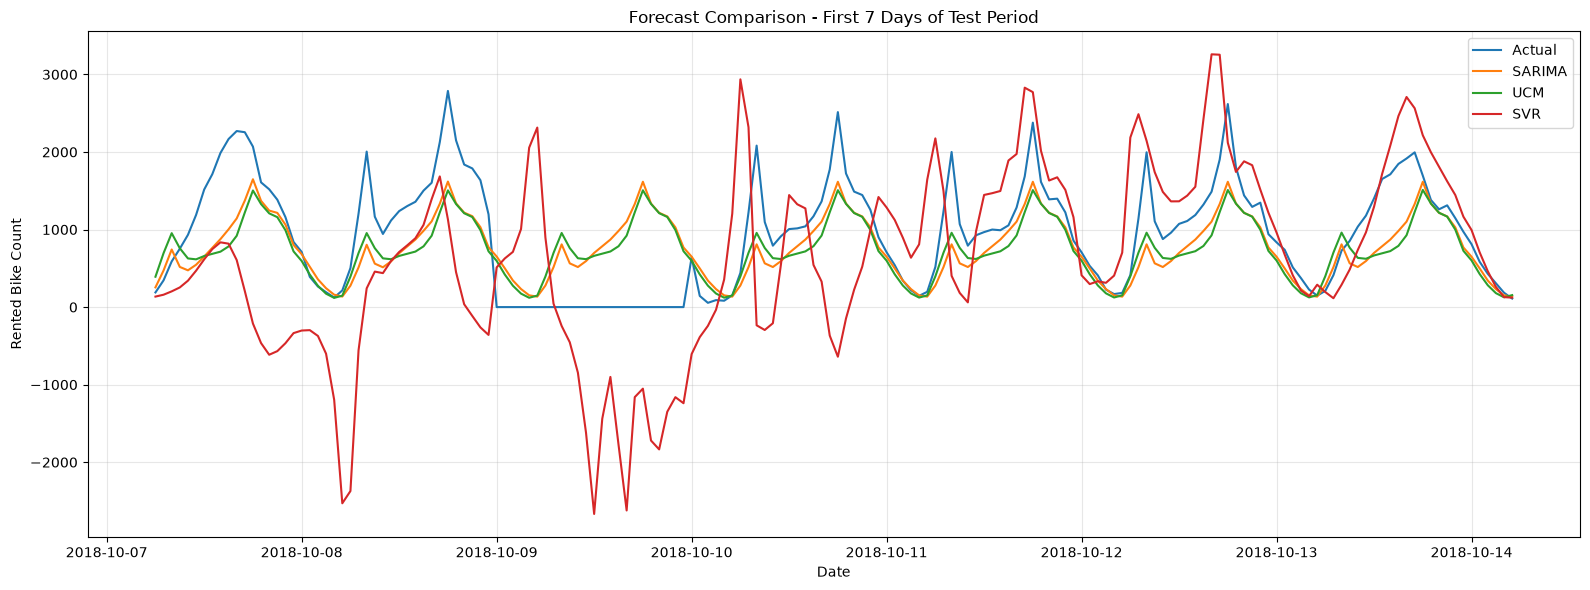

In [12]:
first_week = forecast_comparison.iloc[:168]

plt.figure(figsize=(16, 6))

plt.plot(first_week.index, first_week["Actual"], label="Actual")
plt.plot(first_week.index, first_week["SARIMA"], label="SARIMA")
plt.plot(first_week.index, first_week["UCM"], label="UCM")
plt.plot(first_week.index, first_week["SVR"], label="SVR")

plt.title("Forecast Comparison - First 7 Days of Test Period")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/first_week_forecast_comparison.png",
    dpi=300
)

plt.show()

In [13]:
from statsmodels.stats.diagnostic import acorr_ljungbox

sarima_residuals = final_sarima_fit.resid.dropna()

print("SARIMA FINAL RESIDUAL DIAGNOSTICS")
print("--------------------------------")

print(acorr_ljungbox(
    sarima_residuals,
    lags=[24, 48, 168],
    return_df=True
))

SARIMA FINAL RESIDUAL DIAGNOSTICS
--------------------------------
         lb_stat      lb_pvalue
24    688.026545  8.169141e-130
48    834.818036  4.041528e-144
168  2181.377494   0.000000e+00


In [14]:
ucm_residuals = final_ucm_fit.resid.dropna()

print("UCM FINAL RESIDUAL DIAGNOSTICS")
print("------------------------------")

print(acorr_ljungbox(
    ucm_residuals,
    lags=[24, 48, 168],
    return_df=True
))

UCM FINAL RESIDUAL DIAGNOSTICS
------------------------------
         lb_stat  lb_pvalue
24   2015.634991        0.0
48   2482.642376        0.0
168  6109.311622        0.0


In [15]:
svr_residuals = test - svr_test_forecast

print("SVR FINAL RESIDUAL DIAGNOSTICS")
print("------------------------------")

print(acorr_ljungbox(
    svr_residuals,
    lags=[24, 48, 168],
    return_df=True
))

SVR FINAL RESIDUAL DIAGNOSTICS
------------------------------
          lb_stat  lb_pvalue
24    4616.336886        0.0
48    6845.491452        0.0
168  11852.039151        0.0


In [16]:
# Calculate test-period forecast errors
sarima_test_errors = test - sarima_test_forecast
ucm_test_errors = test - ucm_test_forecast
svr_test_errors = test - svr_test_forecast

# Apply Ljung-Box test to each model's test errors
models_errors = {
    "SARIMA": sarima_test_errors,
    "UCM": ucm_test_errors,
    "SVR": svr_test_errors
}

for model_name, errors in models_errors.items():

    print(f"\n{model_name} TEST ERROR DIAGNOSTICS")
    print("-" * 40)

    print(acorr_ljungbox(
        errors,
        lags=[24, 48, 168],
        return_df=True
    ))


SARIMA TEST ERROR DIAGNOSTICS
----------------------------------------
         lb_stat  lb_pvalue
24   4460.682214        0.0
48   5269.483267        0.0
168  8812.184985        0.0

UCM TEST ERROR DIAGNOSTICS
----------------------------------------
         lb_stat  lb_pvalue
24   4890.956841        0.0
48   5812.881656        0.0
168  9955.596317        0.0

SVR TEST ERROR DIAGNOSTICS
----------------------------------------
          lb_stat  lb_pvalue
24    4616.336886        0.0
48    6845.491452        0.0
168  11852.039151        0.0


In [17]:
diagnostic_results = pd.DataFrame({
    "Model": ["SARIMA", "UCM", "SVR"],
    "Ljung_Box_Lag_24": [
        4460.682214,
        4890.956841,
        4616.336886
    ],
    "Ljung_Box_Lag_48": [
        5269.483267,
        5812.881656,
        6845.491452
    ],
    "Ljung_Box_Lag_168": [
        8812.184985,
        9955.596317,
        11852.039151
    ]
})

diagnostic_results.to_csv(
    "../results/tables/final_residual_diagnostics.csv",
    index=False
)

print(diagnostic_results.to_string(index=False))
print("\nResidual diagnostic table saved successfully!")

 Model  Ljung_Box_Lag_24  Ljung_Box_Lag_48  Ljung_Box_Lag_168
SARIMA       4460.682214       5269.483267        8812.184985
   UCM       4890.956841       5812.881656        9955.596317
   SVR       4616.336886       6845.491452       11852.039151

Residual diagnostic table saved successfully!
